In [1]:
from pathlib import Path
import gc
import time

import numpy as np
import pandas as pd

from nuscenes.nuscenes import NuScenes
from nuscenes.map_expansion.map_api import NuScenesMap

from bst_bev.maps.bst_map_index import BSTMapIndex

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATAROOT = PROJECT_ROOT / "data" / "nuscenes"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RAW_OUTPUT = OUTPUT_DIR / "all_samples_retrieval.csv"
SUMMARY_OUTPUT = OUTPUT_DIR / "all_samples_summary.csv"

MAP_LAYERS = (
    "lane_divider",
    "road_divider",
    "ped_crossing",
)

RADIUS_M = 30.0

# Start here.
# You can extend this later.
ZOOMS = range(18, 27)

print("Dataset:", DATAROOT)
print("Output:", OUTPUT_DIR)

Dataset: /Users/abinavbala/College/Research/BST-BEV/data/nuscenes
Output: /Users/abinavbala/College/Research/BST-BEV/outputs


In [2]:
nusc = NuScenes(
    version="v1.0-mini",
    dataroot=str(DATAROOT),
    verbose=False,
)

print("Scenes:", len(nusc.scene))
print("Samples:", len(nusc.sample))

Scenes: 10
Samples: 404


In [3]:
def get_sample_context(nusc, sample):
    """
    Get scene, map location, and ego XY for one nuScenes sample.
    """

    scene = nusc.get(
        "scene",
        sample["scene_token"],
    )

    log = nusc.get(
        "log",
        scene["log_token"],
    )

    location = log["location"]

    lidar = nusc.get(
        "sample_data",
        sample["data"]["LIDAR_TOP"],
    )

    ego_pose = nusc.get(
        "ego_pose",
        lidar["ego_pose_token"],
    )

    ego_x, ego_y, _ = ego_pose["translation"]

    return {
        "scene_name": scene["name"],
        "location": location,
        "ego_x": ego_x,
        "ego_y": ego_y,
    }

In [4]:
def get_ground_truth_tokens(
    nusc_map,
    ego_x,
    ego_y,
    radius=RADIUS_M,
):
    """
    Retrieve nuScenes vector-map primitives intersecting
    the local square BEV region.
    """

    patch = (
        ego_x - radius,
        ego_y - radius,
        ego_x + radius,
        ego_y + radius,
    )

    records = nusc_map.get_records_in_patch(
        patch,
        list(MAP_LAYERS),
        mode="intersect",
    )

    return {
        (layer, token)
        for layer, tokens in records.items()
        for token in tokens
    }

In [5]:
sample_contexts = []

for sample in nusc.sample:

    context = get_sample_context(
        nusc,
        sample,
    )

    sample_contexts.append({
        "sample_token": sample["token"],
        "timestamp": sample["timestamp"],
        **context,
    })


sample_contexts_df = pd.DataFrame(
    sample_contexts
)

sample_contexts_df.head()

sample_contexts_df.groupby(
    "location"
).size()

location
boston-seaport              163
singapore-hollandvillage    121
singapore-onenorth           39
singapore-queenstown         81
dtype: int64

In [6]:
locations = sorted(
    sample_contexts_df["location"].unique()
)

print("Locations:")
for location in locations:
    print(" -", location)

nusc_maps = {
    location: NuScenesMap(
        dataroot=str(DATAROOT),
        map_name=location,
    )
    for location in locations
}

Locations:
 - boston-seaport
 - singapore-hollandvillage
 - singapore-onenorth
 - singapore-queenstown


In [7]:
ground_truth_cache = {}


for i, row in sample_contexts_df.iterrows():

    nusc_map = nusc_maps[
        row["location"]
    ]

    gt_tokens = get_ground_truth_tokens(
        nusc_map=nusc_map,
        ego_x=row["ego_x"],
        ego_y=row["ego_y"],
        radius=RADIUS_M,
    )

    ground_truth_cache[
        row["sample_token"]
    ] = gt_tokens


print(
    "Cached GT for",
    len(ground_truth_cache),
    "samples",
)

gt_counts = [
    len(tokens)
    for tokens in ground_truth_cache.values()
]

pd.Series(gt_counts).describe()

Cached GT for 404 samples


count    404.000000
mean      10.061881
std        3.955539
min        1.000000
25%        7.000000
50%       11.000000
75%       12.000000
max       20.000000
dtype: float64

In [8]:
def evaluate_sample(
    index,
    row,
    gt_tokens,
):
    """
    Evaluate one sample against one BST index.
    """

    start = time.perf_counter()

    query = index.query_patch(
        center_x=row["ego_x"],
        center_y=row["ego_y"],
        radius=RADIUS_M,

        # None -> use adaptive query sampling
        step_m=None,
    )

    query_time_ms = (
        time.perf_counter() - start
    ) * 1000.0

    bst_tokens = query.tokens

    correct = (
        bst_tokens
        & gt_tokens
    )

    tp = len(correct)
    fp = len(
        bst_tokens - gt_tokens
    )
    fn = len(
        gt_tokens - bst_tokens
    )

    # Undefined precision/recall are stored as NaN.
    # Micro metrics later are computed directly from TP/FP/FN.
    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else np.nan
    )

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,

        "precision": precision,
        "recall": recall,

        "bst_candidates": len(
            bst_tokens
        ),

        "ground_truth": len(
            gt_tokens
        ),

        "cell_width_m": (
            index.cell_width_at(
                row["ego_x"],
                row["ego_y"],
            )
        ),

        "query_step_m": (
            query.actual_step_m
        ),

        "cells_queried": (
            query.cell_count
        ),

        "query_samples": (
            query.sample_count
        ),

        "query_time_ms": (
            query_time_ms
        ),
    }

In [9]:
all_results = []

total_start = time.perf_counter()


for zoom in ZOOMS:

    zoom_start = time.perf_counter()

    print()
    print("=" * 60)
    print(f"ZOOM {zoom}")
    print("=" * 60)

    for location in locations:

        print(
            f"Building index: "
            f"{location}, z={zoom}"
        )

        nusc_map = nusc_maps[
            location
        ]

        index_start = time.perf_counter()

        index = BSTMapIndex(
            nusc_map=nusc_map,
            location=location,
            zoom=zoom,

            # Based on experiment B:
            index_spacing_m=1.0,
            adaptive_index_spacing=False,
        )

        index.build()

        index_time_s = (
            time.perf_counter()
            - index_start
        )

        print(
            f"  occupied cells: "
            f"{len(index):,}"
        )

        print(
            f"  index samples: "
            f"{index.index_sample_count:,}"
        )

        print(
            f"  build time: "
            f"{index_time_s:.2f}s"
        )

        location_samples = (
            sample_contexts_df[
                sample_contexts_df[
                    "location"
                ] == location
            ]
        )

        for _, row in (
            location_samples.iterrows()
        ):

            gt_tokens = (
                ground_truth_cache[
                    row["sample_token"]
                ]
            )

            metrics = evaluate_sample(
                index=index,
                row=row,
                gt_tokens=gt_tokens,
            )

            all_results.append({
                "zoom": zoom,

                "scene": (
                    row["scene_name"]
                ),

                "sample_token": (
                    row["sample_token"]
                ),

                "timestamp": (
                    row["timestamp"]
                ),

                "location": location,

                "ego_x": row["ego_x"],
                "ego_y": row["ego_y"],

                "occupied_index_cells": (
                    len(index)
                ),

                "index_samples": (
                    index.index_sample_count
                ),

                "index_build_time_s": (
                    index_time_s
                ),

                **metrics,
            })

        # We no longer need this index after all
        # samples from this map have been evaluated.
        del index
        gc.collect()

    # --------------------------------------------------
    # Checkpoint after every zoom.
    #
    # This rewrites the same CSV, so if the notebook
    # crashes later you still keep completed zooms.
    # --------------------------------------------------

    df = pd.DataFrame(
        all_results
    )

    df.to_csv(
        RAW_OUTPUT,
        index=False,
    )

    zoom_time = (
        time.perf_counter()
        - zoom_start
    )

    print(
        f"Completed z={zoom} "
        f"in {zoom_time:.1f}s"
    )

    print(
        f"Checkpoint: {RAW_OUTPUT}"
    )


total_time = (
    time.perf_counter()
    - total_start
)

print()
print(
    f"Finished experiment in "
    f"{total_time / 60:.2f} minutes"
)


ZOOM 18
Building index: boston-seaport, z=18
  occupied cells: 176
  index samples: 56,744
  build time: 0.19s
Building index: singapore-hollandvillage, z=18
  occupied cells: 65
  index samples: 15,422
  build time: 0.05s
Building index: singapore-onenorth, z=18
  occupied cells: 66
  index samples: 23,099
  build time: 0.08s
Building index: singapore-queenstown, z=18
  occupied cells: 92
  index samples: 16,960
  build time: 0.06s
Completed z=18 in 5.3s
Checkpoint: /Users/abinavbala/College/Research/BST-BEV/outputs/all_samples_retrieval.csv

ZOOM 19
Building index: boston-seaport, z=19
  occupied cells: 462
  index samples: 56,744
  build time: 0.19s
Building index: singapore-hollandvillage, z=19
  occupied cells: 144
  index samples: 15,422
  build time: 0.05s
Building index: singapore-onenorth, z=19
  occupied cells: 187
  index samples: 23,099
  build time: 0.08s
Building index: singapore-queenstown, z=19
  occupied cells: 196
  index samples: 16,960
  build time: 0.06s
Completed

In [10]:
df.groupby("zoom")["recall"].mean()

summary = (
    df.groupby("zoom")
    .agg(
        tp=("tp", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),

        total_candidates=(
            "bst_candidates",
            "sum",
        ),

        total_ground_truth=(
            "ground_truth",
            "sum",
        ),

        mean_candidates=(
            "bst_candidates",
            "mean",
        ),

        mean_ground_truth=(
            "ground_truth",
            "mean",
        ),

        mean_cells_queried=(
            "cells_queried",
            "mean",
        ),

        median_cells_queried=(
            "cells_queried",
            "median",
        ),

        mean_query_samples=(
            "query_samples",
            "mean",
        ),

        median_query_samples=(
            "query_samples",
            "median",
        ),

        mean_query_time_ms=(
            "query_time_ms",
            "mean",
        ),

        median_query_time_ms=(
            "query_time_ms",
            "median",
        ),

        mean_cell_width_m=(
            "cell_width_m",
            "mean",
        ),

        mean_query_step_m=(
            "query_step_m",
            "mean",
        ),
    )
    .reset_index()
)



In [11]:
summary["precision"] = (
    summary["tp"]
    / (
        summary["tp"]
        + summary["fp"]
    )
)

summary["recall"] = (
    summary["tp"]
    / (
        summary["tp"]
        + summary["fn"]
    )
)

summary["f1"] = (
    2
    * summary["precision"]
    * summary["recall"]
    / (
        summary["precision"]
        + summary["recall"]
    )
)

In [12]:
summary["false_positive_rate_relative"] = (
    summary["fp"]
    / summary["total_ground_truth"]
)

In [13]:
summary = summary[
    [
        "zoom",

        "precision",
        "recall",
        "f1",

        "tp",
        "fp",
        "fn",

        "mean_candidates",
        "mean_ground_truth",

        "mean_cell_width_m",

        "mean_cells_queried",
        "median_cells_queried",

        "mean_query_samples",
        "median_query_samples",

        "mean_query_time_ms",
        "median_query_time_ms",
    ]
]

summary

,zoom,precision,recall,f1,tp,fp,fn,mean_candidates,mean_ground_truth,mean_cell_width_m,mean_cells_queried,median_cells_queried,mean_query_samples,median_query_samples,mean_query_time_ms,median_query_time_ms
0,18,0.356548,1.0,0.525669,4065,7336,0,28.220297,10.061881,136.757520,2.103960,2.0,3721.000000,3721.0,10.863059,10.838605
1,19,0.538482,1.0,0.700017,4065,3484,0,18.685644,10.061881,68.378760,3.646040,4.0,3721.000000,3721.0,10.879388,10.852250
2,20,0.647087,1.0,0.785735,4065,2217,0,15.549505,10.061881,34.189380,7.985149,9.0,3721.000000,3721.0,11.114343,11.060958
3,21,0.800985,1.0,0.889497,4065,1010,0,12.561881,10.061881,17.094690,21.066832,20.0,3721.000000,3721.0,10.906112,10.850063
4,22,0.875889,1.0,0.933839,4065,576,0,11.487624,10.061881,8.547345,67.789604,56.0,3721.000000,3721.0,11.036184,11.034916
5,23,0.939450,1.0,0.968780,4065,262,0,10.710396,10.061881,4.273672,239.913366,196.0,3721.000000,3721.0,11.240666,11.089875
6,24,0.959179,1.0,0.979164,4065,173,0,10.490099,10.061881,2.136836,901.282178,702.0,4140.603960,3721.0,12.653268,11.558625
7,25,0.976225,1.0,0.987969,4065,99,0,10.306931,10.061881,1.068418,3488.933168,2652.0,13778.987624,10404.0,41.841536,31.654625
8,26,0.980463,1.0,0.990135,4065,81,0,10.262376,10.061881,0.534209,13722.019802,10404.0,54652.465347,41209.0,162.737514,122.323063


In [14]:
summary.to_csv(
    SUMMARY_OUTPUT,
    index=False,
)

print(
    f"Raw results:    {RAW_OUTPUT}"
)

print(
    f"Summary results: {SUMMARY_OUTPUT}"
)

Raw results:    /Users/abinavbala/College/Research/BST-BEV/outputs/all_samples_retrieval.csv
Summary results: /Users/abinavbala/College/Research/BST-BEV/outputs/all_samples_summary.csv


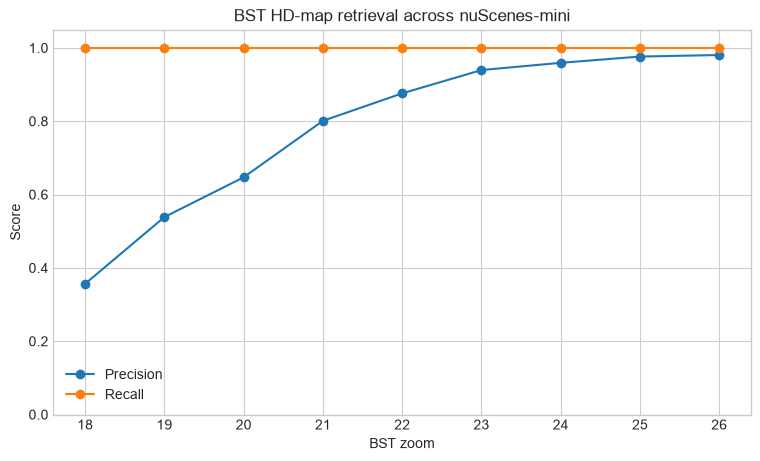

In [15]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary["zoom"],
    summary["precision"],
    marker="o",
    label="Precision",
)

plt.plot(
    summary["zoom"],
    summary["recall"],
    marker="o",
    label="Recall",
)

plt.xlabel("BST zoom")
plt.ylabel("Score")

plt.title(
    "BST HD-map retrieval across nuScenes-mini"
)

plt.ylim(
    0.0,
    1.05,
)

plt.grid(True)
plt.legend()

plt.show()

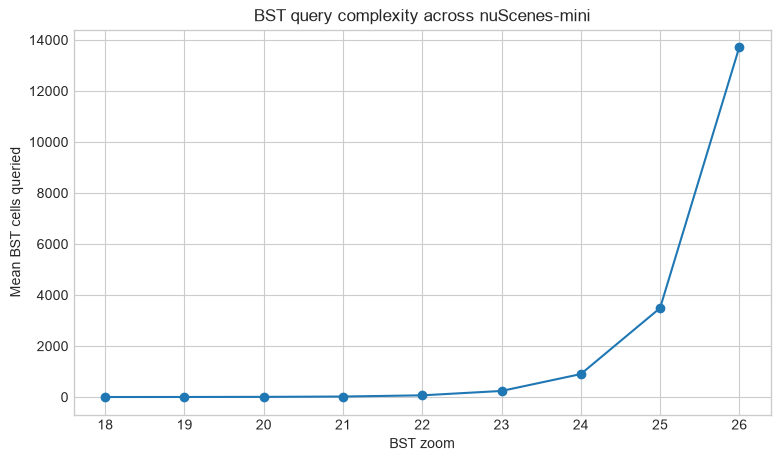

In [16]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary["zoom"],
    summary[
        "mean_cells_queried"
    ],
    marker="o",
)

plt.xlabel("BST zoom")
plt.ylabel(
    "Mean BST cells queried"
)

plt.title(
    "BST query complexity across nuScenes-mini"
)

plt.grid(True)

plt.show()

In [17]:
worst_recall = (
    df[
        df["ground_truth"] > 0
    ]
    .sort_values(
        [
            "recall",
            "zoom",
        ]
    )
    [
        [
            "zoom",
            "scene",
            "location",
            "sample_token",

            "ground_truth",
            "bst_candidates",

            "tp",
            "fp",
            "fn",

            "precision",
            "recall",
        ]
    ]
)

worst_recall.head(20)

,zoom,scene,location,sample_token,ground_truth,bst_candidates,tp,fp,fn,precision,recall
0,18,scene-0103,boston-seaport,3e8750f331d7499e9b5123e9eb70f2e2,6,19,6,13,0,0.315789,1.0
1,18,scene-0103,boston-seaport,3950bd41f74548429c0f7700ff3d8269,7,19,7,12,0,0.368421,1.0
2,18,scene-0103,boston-seaport,c5f58c19249d4137ae063b0e9ecd8b8e,8,19,8,11,0,0.421053,1.0
3,18,scene-0103,boston-seaport,700c1a25559b4433be532de3475e58a9,9,19,9,10,0,0.473684,1.0
4,18,scene-0103,boston-seaport,747aa46b9a4641fe90db05d97db2acea,9,19,9,10,0,0.473684,1.0
5,18,scene-0103,boston-seaport,f4f86af4da3b49e79497deda5c5f223a,9,19,9,10,0,0.473684,1.0
6,18,scene-0103,boston-seaport,6832e717621341568c759151b5974512,9,52,9,43,0,0.173077,1.0
7,18,scene-0103,boston-seaport,c59e60042a8643e899008da2e446acca,9,52,9,43,0,0.173077,1.0
8,18,scene-0103,boston-seaport,fa65a298c01f44e7a182bbf9e5fe3697,10,52,10,42,0,0.192308,1.0
9,18,scene-0103,boston-seaport,a98fba72bde9433fb882032d18aedb2e,10,52,10,42,0,0.192308,1.0


In [18]:
perfect_by_zoom = (
    df[
        df["ground_truth"] > 0
    ]
    .groupby("zoom")
    .agg(
        samples=(
            "sample_token",
            "count",
        ),

        perfect_recall=(
            "recall",
            lambda x: (
                x == 1.0
            ).sum(),
        ),

        perfect_precision=(
            "precision",
            lambda x: (
                x == 1.0
            ).sum(),
        ),
    )
    .reset_index()
)

perfect_by_zoom[
    "perfect_recall_rate"
] = (
    perfect_by_zoom[
        "perfect_recall"
    ]
    / perfect_by_zoom[
        "samples"
    ]
)

perfect_by_zoom[
    "perfect_precision_rate"
] = (
    perfect_by_zoom[
        "perfect_precision"
    ]
    / perfect_by_zoom[
        "samples"
    ]
)

perfect_by_zoom

,zoom,samples,perfect_recall,perfect_precision,perfect_recall_rate,perfect_precision_rate
0,18,404,404,0,1.0,0.000000
1,19,404,404,6,1.0,0.014851
2,20,404,404,21,1.0,0.051980
3,21,404,404,100,1.0,0.247525
4,22,404,404,145,1.0,0.358911
5,23,404,404,211,1.0,0.522277
6,24,404,404,254,1.0,0.628713
7,25,404,404,313,1.0,0.774752
8,26,404,404,327,1.0,0.809406
